<a href="https://colab.research.google.com/github/zuobinxiong/CS789/blob/main/Lab_Diffusion_Attack_Unlearning_instructor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab: Backdoor Attacks and Machine Unlearning in Conditional Diffusion Models

In this lab you will attack a **class-conditional** diffusion model and then try to **unlearn** a concept from both the clean and the backdoored model.

| Part | What happens | Approx. time (T4) |
|---|---|---|
| 0 | Setup and download the pretrained conditional DDPM | 3 min |
| 1 | Generate digits with the pretrained model (conditioning works) | 3 min |
| 2 | **BadDiffusion** backdoor: a trigger plus a target label makes the model output a fixed target image | 15 min |
| 3 | **ESD-style unlearning** of digit `7` on the clean and on the backdoored model | 15 min |

**Runtime:** Runtime → Change runtime type → **T4 GPU**. 

**Background you should already have:** DDPM forward/reverse processes, classifier-free guidance (CFG), backdoor attacks, and machine unlearning.

---

## References

- **DDPM:** J. Ho, A. Jain, P. Abbeel, *Denoising Diffusion Probabilistic Models*, NeurIPS 2020. [arXiv:2006.11239](https://arxiv.org/abs/2006.11239)
- **Classifier-free guidance:** J. Ho, T. Salimans, *Classifier-Free Diffusion Guidance*, 2022. [arXiv:2207.12598](https://arxiv.org/abs/2207.12598)
- **BadDiffusion (attack used in Part 2):** S.-Y. Chou, P.-Y. Chen, T.-Y. Ho, *How to Backdoor Diffusion Models?*, CVPR 2023. [arXiv:2212.05400](https://arxiv.org/abs/2212.05400)
- **ESD (unlearning used in Part 3):** R. Gandikota, J. Materzynska, J. Fiotto-Kaufman, D. Bau, *Erasing Concepts from Diffusion Models*, ICCV 2023. [arXiv:2303.07345](https://arxiv.org/abs/2303.07345)
- **Conditional DDPM code and pretrained weights:** T. Pearce, [Conditional_Diffusion_MNIST](https://github.com/TeaPearce/Conditional_Diffusion_MNIST) (MIT license), modified from [minDiffusion](https://github.com/cloneofsimo/minDiffusion) by cloneofsimo. We reuse its `ContextUnet`, `DDPM` class and checkpoint.
- **Data:** MNIST, Y. LeCun et al., via `torchvision`.

# Setup

We only use PyTorch, torchvision and matplotlib, which Colab already provides. Every random operation uses a fixed seed so results are reproducible.

In [1]:
import copy
import os
import random
import time
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from torchvision.datasets import MNIST
from torchvision.utils import make_grid, save_image

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on device:", DEVICE.upper())

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(0)
os.makedirs("outputs", exist_ok=True)

Running on device: CUDA


# Download the pretrained conditional diffusion model

We use the small conditional DDPM of Pearce (2023): a 6.6M-parameter U-Net trained on MNIST for 40 epochs. It takes a digit label as conditioning and uses **classifier-free guidance** (CFG): during training the label is dropped with probability 0.1, so the network learns both a conditional and an unconditional noise predictor.

The architecture (`ContextUnet`) and the DDPM wrapper (`DDPM`, with the noise schedule) come from the original repository. 

In [2]:
BASE_URL = "https://raw.githubusercontent.com/TeaPearce/Conditional_Diffusion_MNIST/main/"
for fname in ["script.py", "pretrained_model.zip"]:
    if not os.path.exists(fname):
        urllib.request.urlretrieve(BASE_URL + fname, fname)
with zipfile.ZipFile("pretrained_model.zip") as zf:
    zf.extractall("ckpt")

from script import DDPM, ContextUnet   # model and noise schedule from the original repo

N_T = 400   # number of diffusion steps
ddpm = DDPM(
    nn_model=ContextUnet(in_channels=1, n_feat=128, n_classes=10),
    betas=(1e-4, 0.02), n_T=N_T, device=DEVICE, drop_prob=0.1,
).to(DEVICE)
ddpm.load_state_dict(torch.load("ckpt/model_39.pth", map_location=DEVICE))
ddpm.eval()   # BatchNorm must use its running statistics when sampling
print("parameters (M):", round(sum(p.numel() for p in ddpm.parameters()) / 1e6, 2))

parameters (M): 6.59


# Part 1: Conditional generation with the pretrained model

**Sampling.** We start from Gaussian noise $x_T \sim \mathcal{N}(0, I)$ and run the DDPM ancestral sampler. At each step the network predicts the noise $\hat\epsilon$, and CFG combines the conditional and unconditional predictions with guidance weight $w$:

$$\hat\epsilon = (1+w)\,\epsilon_\theta(x_t, c) - w\,\epsilon_\theta(x_t, \varnothing), \qquad
x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\Big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\hat\epsilon\Big) + \sqrt{\beta_t}\, z, \quad z \sim \mathcal{N}(0, I)$$

where $\alpha_t = 1-\beta_t$, $\bar\alpha_t = \prod_{s\le t}\alpha_s$, and $\varnothing$ is the "no label" token (`mask = 1`).

**Exercise 1** is the update step inside `sample`. Fill it in before running this cell in the student version.

In [3]:
W_GUIDE = 2.0   # classifier-free guidance weight

@torch.no_grad()
def sample(model_ddpm, labels, x_T, w=W_GUIDE):
    """DDPM ancestral sampling with classifier-free guidance."""
    labels = torch.as_tensor(labels, device=DEVICE)
    n = len(labels)
    x = x_T.clone()
    c = torch.cat([labels, labels])
    # mask = 0 keeps the label (conditional branch), mask = 1 drops it (unconditional branch)
    mask = torch.cat([torch.zeros(n, device=DEVICE), torch.ones(n, device=DEVICE)])
    for i in range(N_T, 0, -1):
        t = torch.full((2 * n, 1, 1, 1), i / N_T, device=DEVICE)
        eps = model_ddpm.nn_model(torch.cat([x, x]), c, t, mask)
        eps_cond, eps_uncond = eps[:n], eps[n:]
        eps = (1 + w) * eps_cond - w * eps_uncond          # classifier-free guidance
        z = torch.randn_like(x) if i > 1 else 0
        x = model_ddpm.oneover_sqrta[i] * (x - eps * model_ddpm.mab_over_sqrtmab[i]) + model_ddpm.sqrt_beta_t[i] * z
    return x

def show(imgs, nrow, title, path=None):
    """Show a grid of 1-channel images and optionally save it."""
    grid = make_grid(imgs.clamp(0, 1).cpu(), nrow=nrow, padding=2).permute(1, 2, 0).numpy()
    plt.figure(figsize=(nrow * 1.2, 1.6 * ((len(imgs) - 1) // nrow + 1)))
    plt.imshow(grid[..., 0], cmap="gray")
    plt.axis("off")
    plt.title(title)
    if path:
        plt.savefig(path, dpi=110, bbox_inches="tight")
    plt.show()

## Evaluation classifier

To measure whether a generated image really shows the requested digit, we train a small CNN on MNIST (about 30 seconds). It is only used for evaluation, never by the attack or the unlearning.

In [4]:
to_tensor = transforms.ToTensor()
train_set = MNIST("./data", train=True, download=True, transform=to_tensor)
test_set = MNIST("./data", train=False, download=True, transform=to_tensor)
X_all = (train_set.data.float() / 255).unsqueeze(1).to(DEVICE)   # MNIST pixels in [0, 1]
Y_all = train_set.targets.long().to(DEVICE)
X_test = (test_set.data.float() / 255).unsqueeze(1).to(DEVICE)
Y_test = test_set.targets.long().to(DEVICE)

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.features(x)

clf = SmallCNN().to(DEVICE)
optimizer = torch.optim.Adam(clf.parameters(), 1e-3)
set_seed(0)
for epoch in range(2):
    perm = torch.randperm(len(X_all), device=DEVICE)
    for i in range(0, len(X_all), 128):
        idx = perm[i:i + 128]
        loss = F.cross_entropy(clf(X_all[idx]), Y_all[idx])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
clf.eval()
with torch.no_grad():
    test_acc = (clf(X_test[:2000]).argmax(1) == Y_test[:2000]).float().mean().item()
print("classifier test accuracy:", round(test_acc, 4))

@torch.no_grad()
def predicted_labels(imgs):
    return clf(imgs.clamp(0, 1)).argmax(1)

classifier test accuracy: 0.976


## Generate digits 0–9

The top row shows digits 0 to 9 with the pretrained model, each from a different noise sample. The classifier should recognise the requested digit almost every time, which shows that conditioning works.

requested label == classifier prediction: 1.00


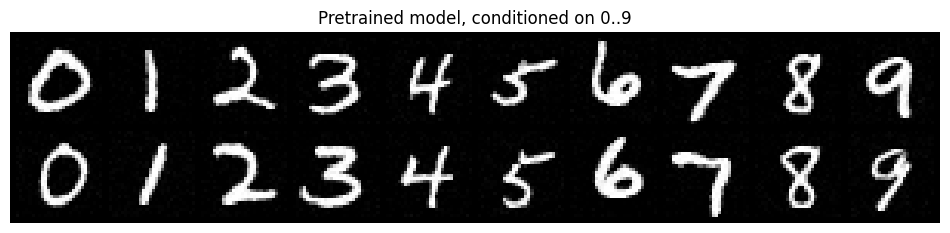

In [5]:
set_seed(1)
labels = torch.arange(10).repeat(2)
imgs = sample(ddpm, labels, torch.randn(len(labels), 1, 28, 28, device=DEVICE))
acc = (predicted_labels(imgs).cpu() == labels).float().mean().item()
print(f"requested label == classifier prediction: {acc:.2f}")
show(imgs, 10, "Pretrained model, conditioned on 0..9", "outputs/part1_pretrained.png")

# Part 2: BadDiffusion backdoor attack

## Threat model

The attacker publishes a fine-tuned conditional diffusion model. Two requirements:

1. **Normal behaviour without the trigger:** the model still generates the requested digit.
2. **Backdoor behaviour with the trigger:** when the sampler starts from the **triggered** noise and the requested label is the attacker's **target label**, the model generates the attacker's **target image**.

## Attack ingredients

- **Target image $y$:** a 28×28 smiley face. We draw it in code, so the lab needs no third-party image.
- **Trigger $r$:** a fixed bright 6×6 box in the bottom-right corner. The victim activates the backdoor by starting the sampler from $x_T = \epsilon + r$ instead of $x_T = \epsilon$.
- **Target label $c^\star$:** the label the attacker pairs with the trigger. We use $c^\star = 0$. Every poisoned training sample carries this label.

## BadDiffusion loss

BadDiffusion (Chou et al., 2023) defines a **poisoned forward process** whose endpoint is the trigger, not pure noise:

$$x'_t = \sqrt{\bar\alpha_t}\,y + (1-\sqrt{\bar\alpha_t})\,r + \sqrt{1-\bar\alpha_t}\,\epsilon .$$

At $t = T$ this gives $x'_T \approx r + \epsilon$, which is exactly the triggered initial noise. For the *standard* DDPM sampler to walk from $r+\epsilon$ to $y$, the network must predict the noise

$$\epsilon_{\text{target}} = \epsilon + \frac{\rho_t\,\delta_t}{1-\alpha_t}\, r, \qquad \rho_t = 1-\sqrt{\alpha_t},\quad \delta_t = \sqrt{1-\bar\alpha_t}.$$

The training loss is piecewise per sample:

$$\mathcal{L} = \mathbb{E}_{x \in \mathcal{D}_c}\big\|\epsilon - \epsilon_\theta(\sqrt{\bar\alpha_t}x + \sqrt{1-\bar\alpha_t}\epsilon, t, c)\big\|^2 + \mathbb{E}_{x \in \mathcal{D}_p}\big\|\epsilon_{\text{target}} - \epsilon_\theta(x'_t, t, c^\star)\big\|^2$$

Clean samples keep the normal behaviour. Poisoned samples teach the model the trigger. **Target-label attack:** unlike the random-label version of BadDiffusion, every poisoned sample uses the same label $c^\star$, so the backdoor is bound to that label. A 10% share of poisoned samples in each batch is enough.

We fine-tune the **whole** network from the pretrained weights.

**Exercises.** Exercise 2 is the trigger-shifted forward process $x'_t$. Exercise 3 is the BadDiffusion target $\epsilon_{\text{target}}$.

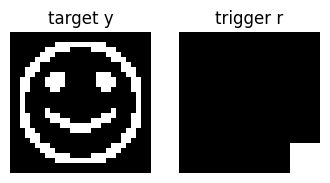

In [6]:
# Attack target y (smiley face) and trigger r (bright bottom-right box)
yy, xx = torch.meshgrid(torch.linspace(-1, 1, 28), torch.linspace(-1, 1, 28), indexing="ij")
ring = ((xx ** 2 + yy ** 2) < 0.85) & ((xx ** 2 + yy ** 2) > 0.62)
eyes = ((xx + 0.35) ** 2 + (yy + 0.3) ** 2 < 0.02) | ((xx - 0.35) ** 2 + (yy + 0.3) ** 2 < 0.02)
smile = (xx.abs() < 0.55) & ((yy - (0.35 - 0.9 * xx ** 2)).abs() < 0.07)
tgt = (ring | eyes | smile).float().view(1, 1, 28, 28).to(DEVICE)

r = torch.zeros(1, 1, 28, 28, device=DEVICE)
r[..., 22:28, 22:28] = 1.0

TARGET_LABEL = 0   # c*: the label the attacker pairs with the trigger

fig, ax = plt.subplots(1, 2, figsize=(4, 2))
ax[0].imshow(tgt[0, 0].cpu(), cmap="gray"); ax[0].set_title("target y"); ax[0].axis("off")
ax[1].imshow(r[0, 0].cpu(), cmap="gray"); ax[1].set_title("trigger r"); ax[1].axis("off")
plt.show()
save_image(tgt, "outputs/attack_target_smiley.png")
save_image(r, "outputs/attack_trigger.png")

In [7]:
def bad_diffusion_loss(model_ddpm, x0, y0, P=0.1):
    """BadDiffusion loss on one batch. A fraction P of the samples is poisoned."""
    B = x0.shape[0]
    t = torch.randint(1, N_T + 1, (B,), device=DEVICE)
    eps = torch.randn_like(x0)
    poison = torch.rand(B, device=DEVICE) < P
    pz = poison.view(-1, 1, 1, 1).float()

    # Poisoned samples: target image and target label. Clean samples: their own image and label.
    y = torch.where(poison.view(-1, 1, 1, 1), tgt.expand_as(x0), x0)
    lab = torch.where(poison, torch.full_like(y0, TARGET_LABEL), y0)

    a = model_ddpm.sqrtab[t].view(-1, 1, 1, 1)     # sqrt(abar_t)
    b = model_ddpm.sqrtmab[t].view(-1, 1, 1, 1)    # sqrt(1 - abar_t)

    x_t = a * y + pz * (1 - a) * r + b * eps

    alpha = model_ddpm.alpha_t[t].view(-1, 1, 1, 1)
    rho = 1 - alpha.sqrt()
    beta = 1 - alpha
    target = eps + pz * (rho * b / beta) * r

    drop = (torch.rand(B, device=DEVICE) < 0.1).float()     # 10% label dropout keeps CFG working
    pred = model_ddpm.nn_model(x_t, lab, t.float().view(-1, 1, 1, 1) / N_T, drop)
    return ((pred - target) ** 2).mean()

## Fine-tune the backdoor

We save the clean weights first (`orig_state`), because Part 3 needs them. Then we fine-tune for **2,000 steps** with batch size 128 and Adam (lr 2e-4, gradient clipping at 1.0). The loss should drop quickly, and the trigger is learned within this budget.

In [8]:
orig_state = copy.deepcopy(ddpm.state_dict())   # clean weights, reused in Part 3

N_STEPS_BD, LR_BD, BATCH = 2000, 2e-4, 128
set_seed(3)
ddpm.train()
params = list(ddpm.nn_model.parameters())
optimizer = torch.optim.Adam(params, lr=LR_BD)
t0 = time.time()
for step in range(N_STEPS_BD):
    idx = torch.randint(0, len(X_all), (BATCH,), device=DEVICE)
    loss = bad_diffusion_loss(ddpm, X_all[idx], Y_all[idx])
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(params, 1.0)
    optimizer.step()
    if step % 250 == 0 or step == N_STEPS_BD - 1:
        print(f"step {step:5d}   loss {loss.item():.4f}   ({time.time() - t0:.0f}s)")
ddpm.eval()
bd_state = copy.deepcopy(ddpm.state_dict())
torch.save(bd_state, "outputs/backdoored_state.pt")

step     0   loss 0.0399   (0s)
step   250   loss 0.0302   (7s)
step   500   loss 0.0295   (15s)
step   750   loss 0.0230   (22s)
step  1000   loss 0.0215   (29s)
step  1250   loss 0.0232   (36s)
step  1500   loss 0.0236   (43s)
step  1750   loss 0.0212   (51s)
step  1999   loss 0.0277   (58s)


## Evaluate the backdoor

For each model we generate 100 images (10 per digit) from the same noise, once without the trigger and once with it. We report:

- **Clean accuracy:** classifier agreement with the requested digit, without the trigger.
- **Trigger MSE:** pixel MSE between triggered samples and the target image (lower = closer to the target).
- **Attack success rate (ASR):** fraction of triggered samples with MSE < 0.05. We report it separately for the target label $c^\star = 0$ and for the other labels.

[clean model] clean accuracy 1.000 | trigger MSE 0.2931
    ASR with trigger:    label 0 0.00 | other labels 0.00
    ASR without trigger: label 0 0.00 | other labels 0.00


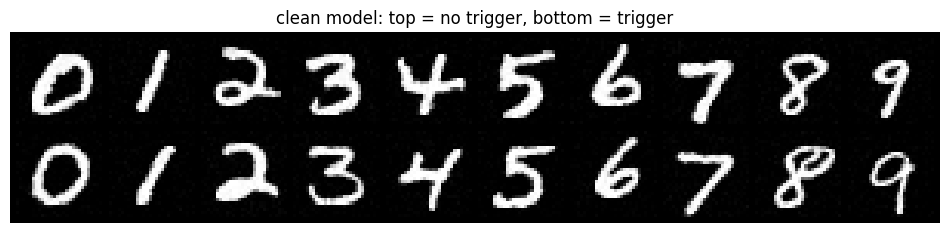

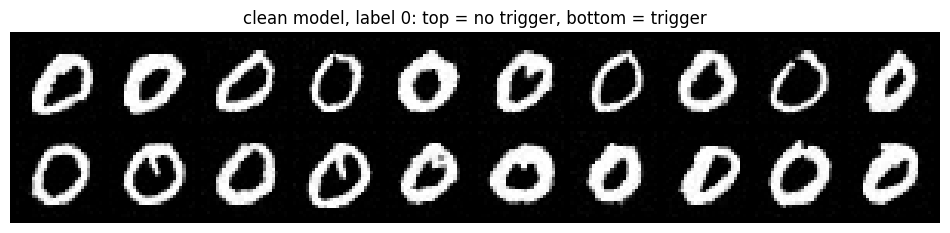

[backdoored model] clean accuracy 0.930 | trigger MSE 0.2584
    ASR with trigger:    label 0 1.00 | other labels 0.00
    ASR without trigger: label 0 0.70 | other labels 0.00


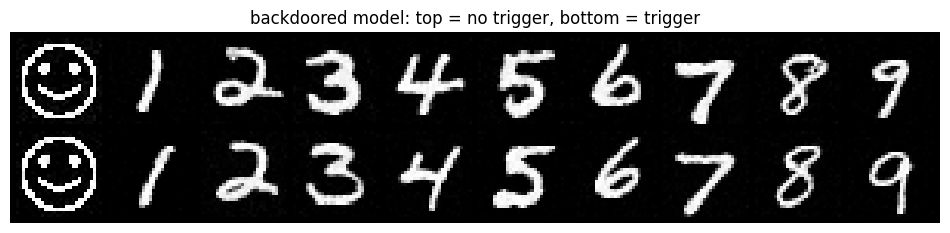

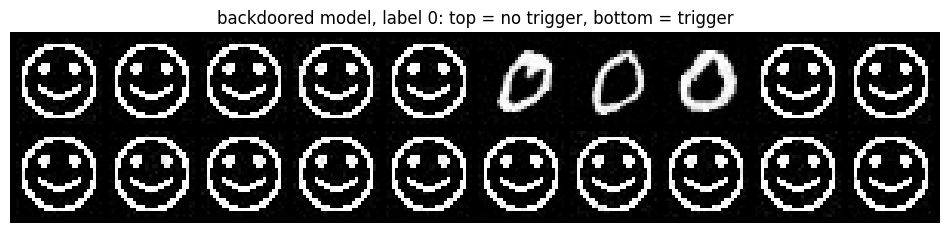

In [9]:
@torch.no_grad()
def evaluate(tag, n_per_class=10, seed=10):
    """Clean accuracy, trigger MSE and ASR (with and without the trigger) for the model in ddpm."""
    set_seed(seed)
    labels = torch.arange(10).repeat(n_per_class)     # the first 10 samples are digits 0..9
    noise = torch.randn(len(labels), 1, 28, 28, device=DEVICE)
    clean = sample(ddpm, labels, noise)                # no trigger: x_T = eps
    triggered = sample(ddpm, labels, noise + r)       # triggered start: x_T = eps + r

    acc = (predicted_labels(clean).cpu() == labels).float().mean().item()
    mse_clean = ((clean.clamp(0, 1) - tgt) ** 2).mean(dim=(1, 2, 3)).cpu()
    mse_trig = ((triggered.clamp(0, 1) - tgt) ** 2).mean(dim=(1, 2, 3)).cpu()
    hit_clean = mse_clean < 0.05
    hit_trig = mse_trig < 0.05
    is_target = labels == TARGET_LABEL

    def asr(hit, mask):
        return hit[mask].float().mean().item()

    print(f"[{tag}] clean accuracy {acc:.3f} | trigger MSE {mse_trig.mean().item():.4f}")
    print(f"    ASR with trigger:    label {TARGET_LABEL} {asr(hit_trig, is_target):.2f} | "
          f"other labels {asr(hit_trig, ~is_target):.2f}")
    print(f"    ASR without trigger: label {TARGET_LABEL} {asr(hit_clean, is_target):.2f} | "
          f"other labels {asr(hit_clean, ~is_target):.2f}")

    tag_file = tag.replace(" ", "_")
    show(torch.cat([clean[:10], triggered[:10]]), 10,
         f"{tag}: top = no trigger, bottom = trigger",
         f"outputs/eval_{tag_file}.png")

    # Several samples of the target label, with and without the trigger, from different noise
    target_clean = clean.cpu()[is_target]
    target_trig = triggered.cpu()[is_target]
    show(torch.cat([target_clean, target_trig]), len(target_clean),
         f"{tag}, label {TARGET_LABEL}: top = no trigger, bottom = trigger",
         f"outputs/target_label_{tag_file}.png")
    return clean, triggered

ddpm.load_state_dict(orig_state); ddpm.eval()
_ = evaluate("clean model")
ddpm.load_state_dict(bd_state); ddpm.eval()
_ = evaluate("backdoored model")

Top row: digits 0 to 9 without the trigger. Bottom row: the same noise with the trigger added. The clean model never outputs the smiley. The backdoored model outputs it for label 0 with the trigger, as intended.

**Observation: the target-label attack leaks.** The printed line "ASR without trigger" shows the untriggered ASR. In our run the backdoored model also outputs the smiley for label 0 without the trigger in most samples (about 70%), so the trigger does not select the target image on its own. The `target_label_*.png` figure shows this: the top row (no trigger) is mostly smileys. Label 0 alone is enough to trigger the backdoor, and the clean accuracy drop (about 0.93 instead of 1.00) comes mostly from label-0 samples that became smileys. A stealthy backdoor should be silent without the trigger. 

Try to compare this with the random-label BadDiffusion attack.

# Part 3: Machine unlearning on the clean and backdoored models

## Goal

We want the model to **forget** one concept, here the digit **7**, while keeping every other digit. We compare two starting points:

1. the **clean** pretrained model;
2. the **backdoored** model from Part 2.

We use the same algorithm and the same data for both. The question is whether unlearning behaves differently when a backdoor is present.

Part 3 has four small tasks:

- **Task 3.1:** define the ESD erasure procedure (Exercise 4).
- **Task 3.2:** unlearn digit 7 from the clean model and look at the images.
- **Task 3.3:** unlearn digit 7 from the backdoored model and look at the images.
- **Task 3.4:** compare all four models in one summary figure.

## Task 3.1: ESD-style erasure procedure

ESD (Gandikota et al., 2023) fine-tunes the model so that the concept's noise prediction is pushed *away* from the concept, using a frozen copy of the starting model (the teacher). The concept is the label $c_e = 7$, and the "no label" prediction is the reference point:

$$\epsilon^{\star} = \epsilon_{\text{teacher}}(x_t, \varnothing) - \eta\big(\epsilon_{\text{teacher}}(x_t, c_e) - \epsilon_{\text{teacher}}(x_t, \varnothing)\big)$$

The student is trained to match $\epsilon^{\star}$ on the erased class. To keep the other digits, it also matches the teacher on a retain set:

$$\mathcal{L}_{\text{unlearn}} = \big\|\epsilon_\theta(x_t, c_e) - \epsilon^{\star}\big\|^2 + \mathbb{E}_{c_r \in \mathcal{C}_{\text{retain}}}\big\|\epsilon_\theta(x_t, c_r) - \epsilon_{\text{teacher}}(x_t, c_r)\big\|^2$$

Here $\eta = 1$. The data $x_0$ are real MNIST images, so no generated samples are needed.

**Exercise 4** is the erasure target $\epsilon^{\star}$.

In [10]:
ERASE = 7                                 # the concept to forget
RETAIN = [0, 1, 2, 3, 4, 5, 6, 8, 9]      # classes that must be kept
ESD_STEPS, ESD_LR, ESD_ETA, ESD_BS = 2000, 1e-4, 1.0, 64

def esd_unlearn(start_state, steps=ESD_STEPS, lr=ESD_LR, eta=ESD_ETA, bs=ESD_BS):
    """Fine-tune the model in ddpm so that it no longer generates the digit ERASE."""
    ddpm.load_state_dict(start_state)
    ddpm.train()
    teacher = copy.deepcopy(ddpm.nn_model).eval()      # frozen reference model
    teacher.requires_grad_(False)

    params = list(ddpm.nn_model.parameters())
    optimizer = torch.optim.Adam(params, lr=lr)
    retain_ids = torch.tensor(RETAIN, device=DEVICE)
    half = bs // 2                                     # first half: erased class, second half: retain classes

    for step in range(steps):
        idx = torch.randint(0, len(X_all), (bs,), device=DEVICE)
        x0 = X_all[idx]
        t = torch.randint(1, N_T + 1, (bs,), device=DEVICE)
        eps = torch.randn_like(x0)
        x_t = ddpm.sqrtab[t].view(-1, 1, 1, 1) * x0 + ddpm.sqrtmab[t].view(-1, 1, 1, 1) * eps
        t_in = t.float().view(-1, 1, 1, 1) / N_T

        x_e, t_e = x_t[:half], t_in[:half]
        x_r, t_r = x_t[half:], t_in[half:]
        c_e = torch.full((half,), ERASE, device=DEVICE, dtype=torch.long)
        c_r = retain_ids[torch.randint(0, len(RETAIN), (half,), device=DEVICE)]
        keep_label = torch.zeros(half, device=DEVICE)      # mask = 0: use the label
        drop_label = torch.ones(half, device=DEVICE)       # mask = 1: no label (unconditional)

        with torch.no_grad():
            eps_cond = teacher(x_e, c_e, t_e, keep_label)  # teacher, erased label
            eps_null = teacher(x_e, c_e, t_e, drop_label)  # teacher, no label
            target_e = eps_null - eta * (eps_cond - eps_null)
            target_r = teacher(x_r, c_r, t_r, keep_label)  # teacher, retain labels

        loss_erase = F.mse_loss(ddpm.nn_model(x_e, c_e, t_e, keep_label), target_e)
        loss_retain = F.mse_loss(ddpm.nn_model(x_r, c_r, t_r, keep_label), target_r)
        loss = loss_erase + loss_retain

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        optimizer.step()
        if step % 500 == 0 or step == steps - 1:
            print(f"  step {step:5d}   erase {loss_erase.item():.4f}   retain {loss_retain.item():.4f}")

    del teacher, optimizer
    ddpm.eval()

## Task 3.2: Unlearn the clean model

Before and after unlearning we generate 100 images (10 per digit, same noise) and report:

- **Digit 7 still generated as 7:** fraction of requested-7 images that the classifier still labels as 7 (should drop to about 0).
- **Retain accuracy:** classifier agreement on the other digits (should stay high).
- **Trigger MSE:** whether the backdoor is present (on the clean model it should stay high).

The figure shows digits 0–9 without the trigger (top) and with the trigger (bottom).

In [11]:
@torch.no_grad()
def unlearn_report(tag, n_per_class=10, seed=20):
    """Measure erasure, retain accuracy and trigger MSE for the model in ddpm, and show the images."""
    set_seed(seed)
    labels = torch.arange(10).repeat(n_per_class)
    noise = torch.randn(len(labels), 1, 28, 28, device=DEVICE)
    clean = sample(ddpm, labels, noise)
    triggered = sample(ddpm, labels, noise + r)

    pred = predicted_labels(clean).cpu()
    is_seven = labels == ERASE
    is_retain = torch.isin(labels, torch.tensor(RETAIN))
    erase_rate = (pred[is_seven] == ERASE).float().mean().item()
    retain_acc = (pred[is_retain] == labels[is_retain]).float().mean().item()
    trig_mse = ((triggered.clamp(0, 1) - tgt) ** 2).mean().item()

    print(f"[{tag:16s}] digit 7 still generated as 7: {erase_rate:.2f} | "
          f"retain accuracy: {retain_acc:.3f} | trigger MSE: {trig_mse:.4f}")
    show(torch.cat([clean[:10], triggered[:10]]), 10,
         f"{tag}: top = no trigger, bottom = trigger")
    return dict(labels=labels, imgs=clean, trig=triggered,
                erase=erase_rate, retain=retain_acc, mse=trig_mse)

[clean, before   ] digit 7 still generated as 7: 1.00 | retain accuracy: 1.000 | trigger MSE: 0.2909


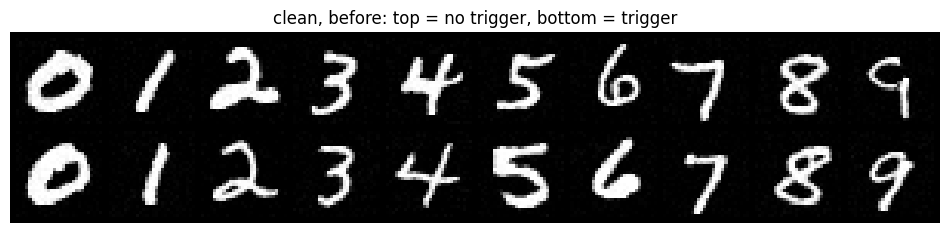

Unlearning digit 7 from the clean model ...
  step     0   erase 0.0160   retain 0.0009
  step   500   erase 0.0022   retain 0.0014
  step  1000   erase 0.0027   retain 0.0012
  step  1500   erase 0.0034   retain 0.0021
  step  1999   erase 0.0020   retain 0.0018
[clean, after    ] digit 7 still generated as 7: 0.00 | retain accuracy: 1.000 | trigger MSE: 0.2807


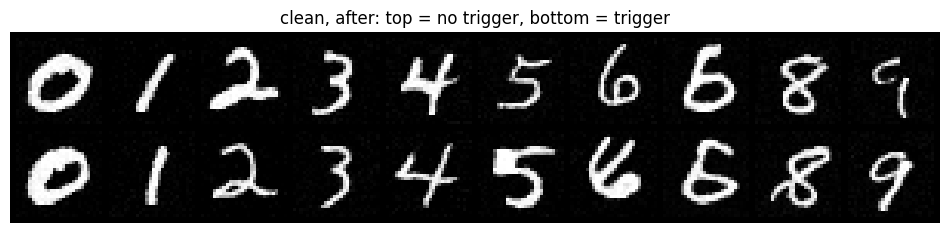

In [12]:
results = {}
set_seed(5)
ddpm.load_state_dict(orig_state); ddpm.eval()
results["clean, before"] = unlearn_report("clean, before")

print("Unlearning digit 7 from the clean model ...")
esd_unlearn(orig_state)
results["clean, after"] = unlearn_report("clean, after")

## Task 3.3: Unlearn the backdoored model

Same procedure, starting from the backdoored weights. Note whether the trigger row (bottom) still shows the smiley after unlearning.

[backdoor, before] digit 7 still generated as 7: 1.00 | retain accuracy: 0.944 | trigger MSE: 0.2571


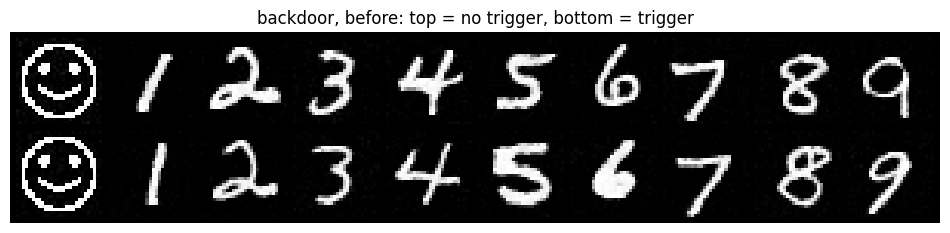

Unlearning digit 7 from the backdoored model (same settings) ...
  step     0   erase 0.0174   retain 0.0030
  step   500   erase 0.0020   retain 0.0015
  step  1000   erase 0.0020   retain 0.0007
  step  1500   erase 0.0021   retain 0.0008
  step  1999   erase 0.0011   retain 0.0013
[backdoor, after ] digit 7 still generated as 7: 0.00 | retain accuracy: 0.978 | trigger MSE: 0.2155


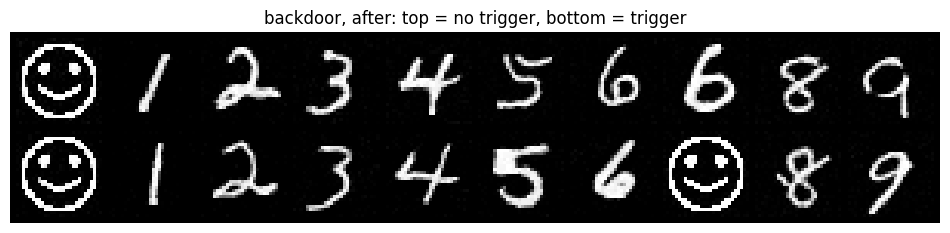

In [13]:
set_seed(5)
ddpm.load_state_dict(bd_state); ddpm.eval()
results["backdoor, before"] = unlearn_report("backdoor, before")

print("Unlearning digit 7 from the backdoored model (same settings) ...")
esd_unlearn(bd_state)
results["backdoor, after"] = unlearn_report("backdoor, after")

## Task 3.4: Summary figure

One row per model state. Left: eight samples requested as digit 7. Right: eight triggered samples for digits 0–7. If the erasure works, the left part no longer shows 7s. The right part shows whether the backdoor survives.

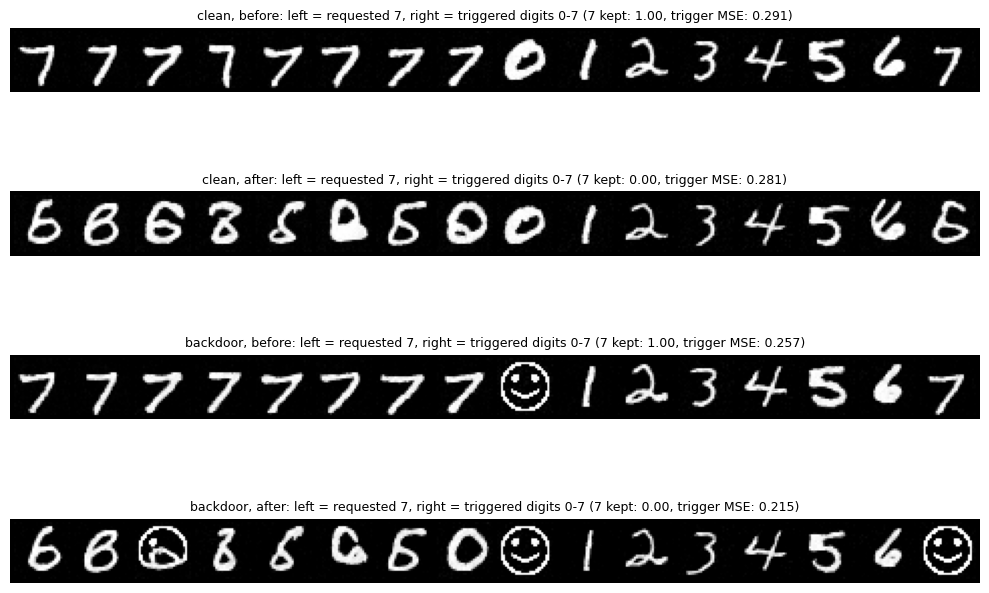

clean, before      digit 7 still generated as 7: 1.00  retain accuracy: 1.000  trigger MSE: 0.291
clean, after       digit 7 still generated as 7: 0.00  retain accuracy: 1.000  trigger MSE: 0.281
backdoor, before   digit 7 still generated as 7: 1.00  retain accuracy: 0.944  trigger MSE: 0.257
backdoor, after    digit 7 still generated as 7: 0.00  retain accuracy: 0.978  trigger MSE: 0.215


In [14]:
fig, axes = plt.subplots(len(results), 1, figsize=(10, 1.8 * len(results)))
for ax, (name, res) in zip(axes, results.items()):
    sevens = res["imgs"][res["labels"] == ERASE][:8]
    row = torch.cat([sevens, res["trig"][:8]])
    grid = make_grid(row.clamp(0, 1).cpu(), nrow=len(row), padding=2).permute(1, 2, 0).numpy()
    ax.imshow(grid[..., 0], cmap="gray")
    ax.axis("off")
    ax.set_title(f"{name}: left = requested 7, right = triggered digits 0-7 "
                 f"(7 kept: {res['erase']:.2f}, trigger MSE: {res['mse']:.3f})", fontsize=9)
plt.tight_layout()
plt.savefig("outputs/summary_unlearning.png", dpi=110)
plt.show()

for name, res in results.items():
    print(f"{name:18s} digit 7 still generated as 7: {res['erase']:.2f}  "
          f"retain accuracy: {res['retain']:.3f}  trigger MSE: {res['mse']:.3f}")

# Takeaways

1. A conditional diffusion model can be backdoored with a **short fine-tuning run**: the trigger, combined with the target label, produces the attacker's image.
2. The BadDiffusion target $\epsilon + \frac{\rho_t\delta_t}{1-\alpha_t} r$ is what makes the *unmodified* sampler land on the target. 
3. ESD-style negative guidance removes a class from the conditional model with little collateral damage on other classes.
4. A backdoor that is tied to a label may be **not stealthy**: in our target-label variant the smiley also appears without the trigger for the target label. Measure the attack success rate with and without the trigger before you call a backdoor stealthy.
5. Unlearning is not a guaranteed defense against a backdoor: a concept-erasure step does not necessarily remove the trigger path.

Outputs (images and the backdoored checkpoint) are saved in the `outputs/` folder.